# Notebook 02: pre-chemical records

This notebook reads the pre-chemical event files (`PreChemical_run<R>_event<E>.txt`) of a Geant4-DNA dump written by `sim.exe`, through `Dump.prechemical_records(allow_missing=True)`. It tabulates the raw modification codes, counts the records with no final position, and plots the positions of the solvated electrons (`e_aq`) in nm.

The default dump is a tiny, seeded run (10 keV electrons, two events). Everything below is a **workflow demonstration**, not a converged result. Run the cells from top to bottom in a fresh kernel; edit `IRT_DUMP` in the next cell to inspect other output.

**Source-check status, stated up front.** The file layout (column order and widths, units nm and eV) was checked against the writer `G4PhysChemIO.cc` and `G4DNAChemistryManager.hh` of the **Geant4 11.4.1** source tree. The dump's manifest reports the runtime tag printed below, which is **not** the version of that source tree, so the field meanings are **unverified against the source matching the binary**. The file is also **not a complete physical-step record** (see the reading notes).

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from g4utils.DnaChem import Dump

dev_dir = os.environ.get('DEV_DIR')
if not dev_dir:
    raise RuntimeError(
        'DEV_DIR is unset. Run ~/dotfiles/scripts/windows/setup-dev-env.ps1 and restart the shell before using this notebook.'
    )
DEV_DIR = Path(dev_dir)

DEFAULT_RUN_ROOT = (
    DEV_DIR / 'GEANT4' / 'SIM' / 'dnachem-min'
    / '.scratch' / 'tests'
    / '2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the'
)

# Edit this path for a different dump (unprefixed, with its own Manifest.json).
IRT_DUMP = DEFAULT_RUN_ROOT / 'irt'

README_HINT = 'See notebooks/README.md ("Reproduce the runs") to regenerate the demonstration data.'

if not hasattr(Dump, 'prechemical_records'):
    raise ImportError(f'The installed G4Utils lacks Dump.prechemical_records. {README_HINT}')
manifest_file = IRT_DUMP / 'Manifest.json'
if not manifest_file.is_file() or manifest_file.stat().st_size == 0:
    raise FileNotFoundError(f'No usable Manifest.json at {manifest_file}. Edit IRT_DUMP or regenerate. {README_HINT}')

dump = Dump.from_manifest(manifest_file)
print(f'Dump: {dump.path.resolve()}')
print(f'Geant4 runtime tag in the manifest: {dump.manifest.geant4Version}')
print('Geant4 source consulted for the layout check: 11.4.1 (not necessarily the binary version)')

Dump: C:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\irt
Geant4 runtime tag in the manifest: geant4-11-04-patch-01
Geant4 source consulted for the layout check: 11.4.1 (not necessarily the binary version)


## 1. Load the records

`prechemical_records(allow_missing=True)` returns one row per record with `run`, `event`, `parent_id`, `molecule`, the **raw** `electron_modification` string, `energy_eV`, the parent position (`parent_*_nm`) and the nullable final position (`x_nm`, `y_nm`, `z_nm`). Rows are records, not event-normalized counts. With `allow_missing=True`, a dump that has no pre-chemical output gives an empty frame instead of an error; files that the manifest lists but that are missing on disk still raise.

In [2]:
rec = dump.prechemical_records(allow_missing=True)
if rec.empty:
    raise ValueError(f'No pre-chemical records in this dump. {README_HINT}')

n_files = rec[['run', 'event']].drop_duplicates().shape[0]
print(f'{len(rec)} records from {n_files} event files')
display(rec.groupby(['run', 'event']).size().rename('records').to_frame())
display(rec[['run', 'event', 'parent_id', 'molecule', 'electron_modification', 'energy_eV',
             'parent_x_nm', 'parent_y_nm', 'parent_z_nm', 'x_nm', 'y_nm', 'z_nm']].head(8))

2152 records from 2 event files


records
run event         
0   0         1080
    1         1072

,run,event,parent_id,molecule,electron_modification,energy_eV,parent_x_nm,parent_y_nm,parent_z_nm,x_nm,y_nm,z_nm
0,0,0,1,H2O,0:4,10.79,0.000000,0.000000,2.725889,<NA>,<NA>,<NA>
1,0,0,1,H2O,0:4,10.79,-0.500397,-1.097857,98.859680,<NA>,<NA>,<NA>
2,0,0,1,H2O,0:4,10.79,-0.520728,-0.948461,110.041300,<NA>,<NA>,<NA>
3,0,0,1,H2O,0:1,32.30,2.060651,0.622172,126.331100,<NA>,<NA>,<NA>
4,0,0,1,H2O,0:1,32.30,30.908060,13.303170,210.642400,<NA>,<NA>,<NA>
5,0,0,1,H2O,0:4,10.79,41.423710,18.044470,232.077200,<NA>,<NA>,<NA>
6,0,0,1,H2O,0:3,13.39,51.384810,21.855190,253.103700,<NA>,<NA>,<NA>
7,0,0,1,H2O,0:3,13.39,62.214840,24.824230,273.455800,<NA>,<NA>,<NA>


## 2. Raw modification codes

The codes are kept exactly as written. What the writer shows in the 11.4.1 source:

- `H2O` rows (`CreateWaterMolecule`) write `<modification>:<level>`, where `<modification>` is the integer value of the C++ enum `ElectronicModification` (`eIonizedMolecule`=0, `eExcitedMolecule`=1, `eDissociativeAttachment`=2, in `G4DNAChemistryManager.hh`) and `<level>` is the electronic level (shell or excitation level) passed by the physics model. The file header itself says `1)io/ex=0/1` and `2)level=0...5`.
- `e_aq` rows (`CreateSolvatedElectron`) always write the literal code `-1`, with the electron's kinetic energy in the energy column.

The table below counts the codes as found. **Not verified**: the level numbering depends on the physics model that called the writer, and I did not trace which model produced which level; the labels above are the enum names and are not checked against the source matching the binary.

In [3]:
codes = (rec.groupby(['molecule', 'electron_modification'])
            .agg(records=('energy_eV', 'size'), mean_energy_eV=('energy_eV', 'mean'))
            .reset_index())
display(codes)

rec_label = 'run ' + rec['run'].astype(str) + ' ev ' + rec['event'].astype(str)
by_event = pd.crosstab(rec['electron_modification'].astype(str), rec_label.astype(str))
display(by_event)

# Consistency with the writer: e_aq rows carry code -1, water rows carry <0|1|2>:<level>.
assert set(rec.loc[rec['molecule'] == 'e_aq', 'electron_modification']) == {'-1'}
assert rec.loc[rec['molecule'] == 'H2O', 'electron_modification'].str.fullmatch(r'[0-9]+:[0-9]+').all()

,molecule,electron_modification,records,mean_energy_eV
0,H2O,0:1,49,32.300000
1,H2O,0:2,103,16.050000
2,H2O,0:3,308,13.390000
3,H2O,0:4,554,10.790000
4,H2O,1:0,10,13.770000
5,H2O,1:1,7,12.610000
6,H2O,1:2,30,11.240000
7,H2O,1:3,44,10.000000
8,H2O,1:4,31,8.220000
9,H2O,2:5,17,0.000000


col_0,run 0 ev 0,run 0 ev 1
electron_modification,,
-1,504,495
0:1,25,24
0:2,43,60
0:3,161,147
0:4,282,272
1:0,7,3
1:1,2,5
1:2,13,17
1:3,21,23


## 3. Records without a final position

The final position columns are written only when the writer received a non-null final position (`CreateSolvatedElectron` with `finalPosition != nullptr`); water rows never carry one. `G4Utils` keeps these as nulls and does not substitute the parent position. The count below is by molecule.

In [4]:
null_final = rec[['x_nm', 'y_nm', 'z_nm']].isna().all(axis=1)
partial = rec[['x_nm', 'y_nm', 'z_nm']].isna().any(axis=1) & ~null_final
assert not partial.any(), 'Some rows have a partly missing final position.'
summary = (pd.DataFrame({'molecule': rec['molecule'], 'null final position': null_final})
             .groupby('molecule')['null final position']
             .agg(records='size', null_final_position='sum'))
display(summary)
print(f'Records with a null final position: {int(null_final.sum())} of {len(rec)}')

Records with a null final position: 1153 of 2152


,records,null_final_position
molecule,,
H2O,1153,1153
e_aq,999,0


## 4. Solvated-electron positions

Each `e_aq` record has the position of the incoming track (`parent_*_nm`) and, when present, a final position (`x_nm`, `y_nm`, `z_nm`), all in **nm**. The plot shows the final positions projected on the x-z plane and the distance (nm) between the two positions of each record. Only rows with a final position are plotted; none are dropped silently, the count is printed.

e_aq records: 999; plotted (final position present): 999; without: 0


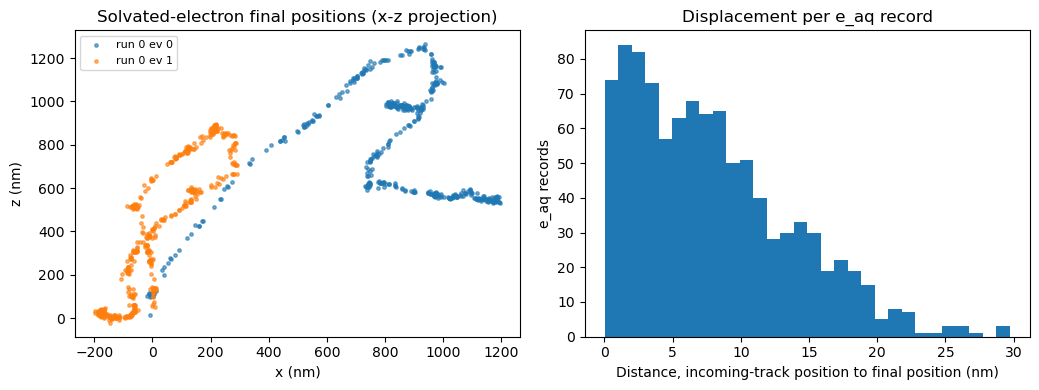

,count,mean,std,min,25%,50%,75%,max
shift_nm,999.0,7.907152,5.768716,0.028255,3.127796,6.93337,11.378274,29.711657


In [5]:
eaq = rec[rec['molecule'] == 'e_aq']
with_final = eaq[eaq[['x_nm', 'y_nm', 'z_nm']].notna().all(axis=1)].copy()
print(f'e_aq records: {len(eaq)}; plotted (final position present): {len(with_final)}; without: {len(eaq) - len(with_final)}')
assert not with_final.empty, 'No e_aq record has a final position.'

for c in ('x_nm', 'y_nm', 'z_nm'):
    with_final[c] = with_final[c].astype(float)
with_final['shift_nm'] = (
    (with_final['x_nm'] - with_final['parent_x_nm']) ** 2
    + (with_final['y_nm'] - with_final['parent_y_nm']) ** 2
    + (with_final['z_nm'] - with_final['parent_z_nm']) ** 2
) ** 0.5

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for (run, event), g in with_final.groupby(['run', 'event']):
    axes[0].scatter(g['x_nm'], g['z_nm'], s=6, alpha=0.6, label=f'run {run} ev {event}')
axes[0].set_xlabel('x (nm)'); axes[0].set_ylabel('z (nm)')
axes[0].set_title('Solvated-electron final positions (x-z projection)')
axes[0].legend(fontsize=8)
axes[1].hist(with_final['shift_nm'], bins=30, color='tab:blue')
axes[1].set_xlabel('Distance, incoming-track position to final position (nm)')
axes[1].set_ylabel('e_aq records')
axes[1].set_title('Displacement per e_aq record')
fig.tight_layout()
plt.show()
display(with_final['shift_nm'].describe().rename('shift_nm').to_frame().T)

## Reading notes

- **Not a complete physical-step record.** The file lists only the molecules and solvated electrons handed to the chemistry stage, one row each. It does not list every physical interaction (compare `PhysicsInteractions` in notebook 01), nor energy deposits.
- **Verification status.** Layout and the enum behind the `0|1|2` first code field were read in the Geant4 11.4.1 source (`G4PhysChemIO.cc`, `G4DNAChemistryManager.hh`). The manifest reports the runtime tag printed at the top of this notebook, so the field meanings are unverified against the source matching the binary, and the level numbers were not traced to individual physics models. Treat code interpretations as provisional.
- Codes are raw strings and counts are record counts, not G-values and not per-event normalized.
- The meaning of the `e_aq` final position (for example whether it is a thermalization or a delocalization position) was not checked in the source here, so the plot shows it only as "final position".
- With two events these numbers carry large statistical uncertainty; use many events for any physical conclusion.